In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Bridge Collapse Simulation Under Strong Winds

Suppose we want to estimate the probability of a bridge collapsing under strong winds. We know the following:

- The wind speed follows a distribution centred at $40$ km/h, with a standard deviation of $10$ km/h.
- The bridge collapses if the wind speed is greater than or equal to $80$ km/h.

We can estimate this probability using a Monte Carlo simulation. For example, we can run the simulation $100{,}000$ times, sampling the wind speed in each iteration and counting the number of times it exceeds or equals $80$ km/h.

The estimated probability is then given by:

$$
    p_{\mathrm{MC}} = \frac{1}{N}\sum_{i=1}^{N}\mathbb{I}(v_i \geq 80)
$$

where $N=100000$, $v_i$ is the wind speed sampled in the $i$-th simulation, and $\mathbb{I}$ is the indicator function, such that

$$
\mathbb{I}(v_i \geq 80) =
\begin{cases}
1, & v_i \geq 80, \\
0, & v_i < 80.
\end{cases}
$$

In [2]:
samples = np.random.normal(loc=40, scale=10, size=100_000)

In [3]:
collapse_threshold = 80
collapse_samples = samples[samples >= collapse_threshold]

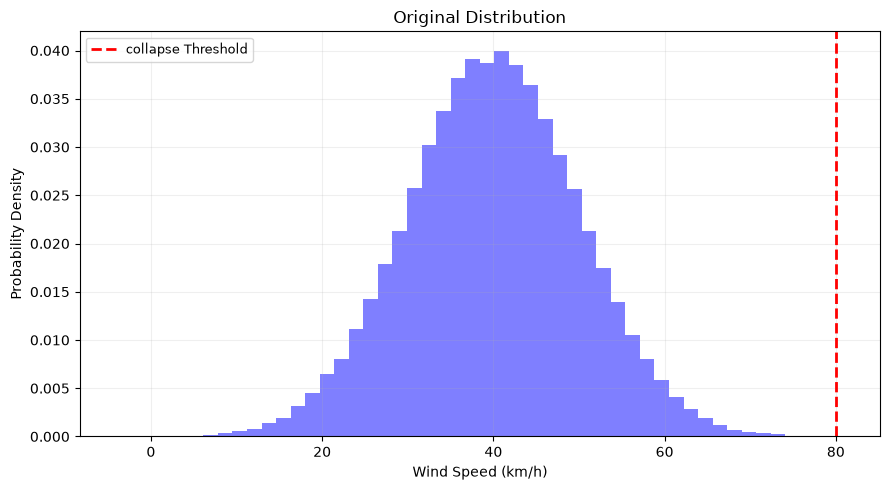

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(samples, bins=50, density=True, alpha=0.5, color='blue')
ax.axvline(collapse_threshold, color='red', linestyle='dashed', linewidth=2, label='collapse Threshold')
ax.set(xlabel='Wind Speed (km/h)', ylabel='Probability Density', title='Original Distribution')
ax.legend(frameon=True, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Why Do Rare Events Require More Simulations?

One important thing to note here is that the wind speed threshold for bridge collapse ($80$ km/h) lies $4\sigma$ above the mean of the wind speed distribution:

$$
z = \frac{80-40}{10} = 4
$$

Assuming a Gaussian wind speed distribution, this makes bridge collapse a rare event, with a probability of approximately $3.17 \times 10^{-5}$.

Although the Central Limit Theorem tells us that the sampling distribution of our estimated probability approaches a Gaussian distribution as the number of simulations increases, accurately estimating the probability of rare events requires a considerably larger number of simulations.

This is because the standard error of the Monte Carlo probability estimate is given by:

$$
\sigma_{\hat{p}} = \sqrt{\frac{p(1-p)}{N}}
$$

For rare events, where $p \ll 1$, we can approximate this as:

$$
\sigma_{\hat{p}} \approx \sqrt{\frac{p}{N}}
$$

Consequently, the relative error becomes:

$$
\frac{\sigma_{\hat{p}}}{p} \approx \frac{1}{\sqrt{Np}}
$$

This is the key result! It tells us that the relative error depends on the expected number of times the event occurs, $Np$, rather than just the total number of simulations.

For example, if we want a relative standard error of approximately $10\%$, we require:

$$
\frac{1}{\sqrt{Np}} = 0.1
$$

Rearranging, we obtain:

$$
N = \frac{100}{p}
$$

For our bridge collapse example, this gives:

$$
N = \frac{100}{3.17 \times 10^{-5}}
\approx 3.15 \times 10^6
$$

Therefore, we need approximately $3.15$ million simulations just to achieve a relative standard error of $10\%$.

**Key takeaway:** In ordinary Monte Carlo simulations, the relevant quantity is not simply the total number of simulations, but the expected number of times the event occurs, $Np$. This is why estimating the probability of rare events can become computationally expensive.

In [5]:
collapse_probability = len(collapse_samples) / len(samples)
standard_error = np.sqrt(collapse_probability * (1 - collapse_probability) / len(samples))

print(f"Estimated probability of collapse: {collapse_probability} ± {standard_error}")

print("Relative standard error:", standard_error / collapse_probability)

Estimated probability of collapse: 2e-05 ± 1.4141994201667599e-05
Relative standard error: 0.7070997100833799


We observe that the relative standard error (RSE) is approximately $70\%$, which is quite high, and we would like to reduce it. However, achieving a sufficiently small RSE using standard Monte Carlo simulations can be computationally expensive, particularly when estimating the probability of rare events.

# Moving to Importance Sampling

To address this, we employ a technique called **Importance Sampling**. Instead of sampling wind speeds from the original distribution, $p_{\text{real}}(x)$, we introduce a modified distribution, $q_{\text{storm}}(x)$, centred at $80\,\text{km/h}$ while keeping the same standard deviation.

With this modified distribution, a significantly larger fraction of the simulated events result in bridge collapse. However, these events are over-represented compared to their actual occurrence under the real wind-speed distribution. We therefore correct for this bias by assigning each sample a weight given by the likelihood ratio:

$$
w(x) = \frac{p_{\text{real}}(x)}{q_{\text{storm}}(x)}
$$

This reweighting ensures that, despite sampling from a different distribution, our estimate remains an unbiased estimate of the actual probability of bridge collapse.

In [6]:
storm_distribution_samples = np.random.normal(loc=80, scale=10, size=10_000)

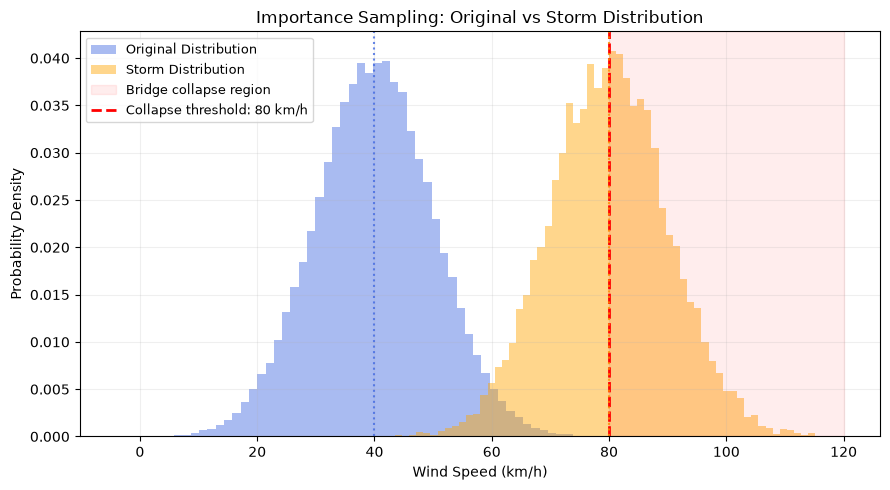

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(samples, bins=60, density=True, alpha=0.45, color='royalblue', label=fr'Original Distribution')
ax.hist(storm_distribution_samples, bins=60, density=True, alpha=0.45, color='orange', label=fr'Storm Distribution')

ax.axvspan(collapse_threshold, 120, color='red', alpha=0.07, label='Bridge collapse region')
ax.axvline(collapse_threshold, color='red', linestyle='--', linewidth=2, label=fr'Collapse threshold: {collapse_threshold:.0f} km/h')

ax.axvline(np.mean(samples), color='royalblue', linestyle=':', alpha=0.8)
ax.axvline(np.mean(storm_distribution_samples), color='darkorange', linestyle=':', alpha=0.8)

ax.set(xlabel='Wind Speed (km/h)', ylabel='Probability Density', title='Importance Sampling: Original vs Storm Distribution')
ax.legend(frameon=True, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [8]:
real_mean = 40
storm_mean = 80

log_p_real = -0.5 * ((storm_distribution_samples - real_mean) / 10) ** 2
log_q_storm = -0.5 * ((storm_distribution_samples - storm_mean) / 10) ** 2

weight = np.exp(log_p_real - log_q_storm)

Now we can have an estimate of our probability of bridge collapse using:

$$
    \hat{p} = \frac{1}{N} \sum_{i = 1}^{N} \mathbb{I}(x_i \geq 80) w(x_i)
$$

In [9]:
is_probability_estimate = np.sum(weight[storm_distribution_samples >= collapse_threshold]) / len(storm_distribution_samples)

In [10]:
contributions = weight * (storm_distribution_samples >= collapse_threshold)
is_standard_error = np.std(contributions, ddof=1) / np.sqrt(len(contributions))

In [11]:
print(f"Estimated probability of calamity using importance sampling: {is_probability_estimate} ± {is_standard_error}")

print(f"Relative standard error using importance sampling: {is_standard_error / is_probability_estimate}")

Estimated probability of calamity using importance sampling: 3.218417940521406e-05 ± 6.787540231459848e-07
Relative standard error using importance sampling: 0.02108967932971508


We can see that even with fewer number of simulations we still achieve very small relative standard error of just $2 \%$.

Credit: [Youtube Vide](https://www.youtube.com/shorts/s9IvQEXzqzg)